# Bài 4 - Sinh ảnh từ văn bản với Stable Diffusion

- Họ và tên: Nguyễn Đăng Thới Toàn
- MSHV: 25C15062
- Code được gợi ý bởi Codex/ChatGPT - đã được học viên review cẩn thận.
##  Mục tiêu

- Notebook sử dụng SDXL Base 1.0 để thực hiện bài toán sinh ảnh từ văn bản. Prompt chính được dùng trong thí nghiệm là: **"an astronaut riding a horse on the moon, detailed, cinematic lighting"**. 
- Nội dung thí nghiệm gồm:
   - Sinh ảnh bằng pipeline của Diffusers.
   - Khảo sát ảnh hưởng của độ phân giải đầu vào, guidance scale, số bước khử nhiễu và random seed đến kết quả sinh ảnh.
   - Tải riêng các thành phần của SDXL gồm VAE, UNet, hai CLIP text encoder và scheduler, sau đó tự triển khai vòng khử nhiễu.
   - Đối chiếu kết quả giữa cách chạy pipeline chuẩn và cách triển khai thủ công.

- Đồng thời mở rộng thêm:
   - So sánh nhiều scheduler khác nhau.
   - Trực quan hóa các trạng thái trung gian trong quá trình khử nhiễu.
   - So sánh ảnh đầu ra giữa SDXL Base và SDXL Refiner.

## 0. Thiết lập môi trường

In [ ]:
import csv
import gc
import time
import logging
import warnings
import os
from pathlib import Path

import numpy as np
import torch
import diffusers
import transformers
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from diffusers import (
    AutoencoderKL, StableDiffusionXLPipeline, UNet2DConditionModel,
    DDIMScheduler, DPMSolverMultistepScheduler,
)
from diffusers.image_processor import VaeImageProcessor
from transformers import CLIPTokenizer, CLIPTextModel, CLIPTextModelWithProjection
from huggingface_hub.utils import disable_progress_bars
from transformers.utils import logging as transformers_logging
from diffusers.utils import logging as diffusers_logging

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
disable_progress_bars()
transformers_logging.disable_progress_bar()
diffusers_logging.disable_progress_bar()
transformers_logging.set_verbosity_error()
diffusers_logging.set_verbosity_error()


warnings.filterwarnings('ignore', message='`upcast_vae` is deprecated', category=FutureWarning)
class _VaeCastNoiseFilter(logging.Filter):
    def filter(self, record):
        return not record.getMessage().startswith(
            'There are modules in AutoencoderKL that should be kept in float32: []')
logging.getLogger('diffusers.models.modeling_utils').addFilter(_VaeCastNoiseFilter())

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.float16 if DEVICE == 'cuda' else torch.float32
MODEL_ID = 'stabilityai/stable-diffusion-xl-base-1.0'
VARIANT = 'fp16' if DEVICE == 'cuda' else None
PROMPT = 'an astronaut riding a horse on the moon, detailed, cinematic lighting'
NEGATIVE_PROMPT = ''  # Dùng prompt rỗng ở nhánh unconditional của CFG.
SEED = 42
HEIGHT, WIDTH = 1024, 1024
STEPS, GUIDANCE = 25, 7.5
OUT = Path('results_bai4_sdxl')
OUT.mkdir(exist_ok=True)

print('GPU:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'Không có GPU (chạy CPU rất chậm)')
if DEVICE == 'cuda':
    print('VRAM tổng:', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), 'GiB')
print('torch:', torch.__version__, 'diffusers:', diffusers.__version__,
      'transformers:', transformers.__version__)
print('model:', MODEL_ID, '| seed:', SEED, '| output:', OUT)

In [ ]:
def initial_latents(unet, vae, height, width, seed):
    scale = 2 ** (len(vae.config.block_out_channels) - 1)
    assert height % scale == 0 and width % scale == 0
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    return torch.randn(
        (1, unet.config.in_channels, height // scale, width // scale),
        generator=generator, device=DEVICE, dtype=DTYPE,
    )

def measure(call):
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    result = call()
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
        peak_gib = torch.cuda.max_memory_allocated() / 1024**3
    else:
        peak_gib = None
    return result, time.perf_counter() - start, peak_gib

def save_table(rows, name):
    if not rows:
        return
    path = OUT / name
    with path.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    display(rows)
    print('Đã lưu:', path)

def image_grid(items, columns=3, thumb=(320, 320)):
    rows = (len(items) + columns - 1) // columns
    label_height = 54
    tile_height = thumb[1] + label_height
    canvas = Image.new('RGB', (columns * thumb[0], rows * tile_height), '#e2e8f0')
    draw = ImageDraw.Draw(canvas)
    try:
        font = ImageFont.truetype('DejaVuSans.ttf', 23)
    except OSError:
        font = ImageFont.load_default()
    for index, (label, image) in enumerate(items):
        x = (index % columns) * thumb[0]
        y = (index // columns) * tile_height
        draw.rectangle((x, y, x + thumb[0] - 1, y + label_height - 1), fill='#0f172a')
        draw.text((x + 12, y + 12), label, font=font, fill='white')
        copy = image.copy()
        copy.thumbnail(thumb)
        canvas.paste(copy, (x + (thumb[0] - copy.width) // 2,
                            y + label_height + (thumb[1] - copy.height) // 2))
    return canvas

## 1. Sinh ảnh đầu tiên bằng SDXL pipeline

In [ ]:
load_kwargs = dict(dtype=DTYPE, use_safetensors=True, add_watermarker=False)
if VARIANT is not None:
    load_kwargs['variant'] = VARIANT
pipe = StableDiffusionXLPipeline.from_pretrained(MODEL_ID, **load_kwargs).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
_ = pipe(PROMPT, negative_prompt=NEGATIVE_PROMPT, num_inference_steps=2,
         generator=torch.Generator(device=DEVICE).manual_seed(SEED),
         output_type='latent').images  

def pipeline_image(pipe, prompt=PROMPT, height=HEIGHT, width=WIDTH,
                   guidance=GUIDANCE, steps=STEPS, seed=SEED, latents=None):
    raw = initial_latents(pipe.unet, pipe.vae, height, width, seed) if latents is None else latents
    return pipe(
        prompt=prompt, negative_prompt=NEGATIVE_PROMPT, height=height, width=width,
        original_size=(height, width), target_size=(height, width),
        crops_coords_top_left=(0, 0), guidance_scale=guidance,
        num_inference_steps=steps, latents=raw.clone(),
    ).images[0]

first_image, first_seconds, first_peak = measure(lambda: pipeline_image(pipe))
first_image.save(OUT / 'first_image.png')
display(first_image)
print(f'Thời gian: {first_seconds:.2f}s | VRAM tensor đỉnh: {first_peak:.2f} GiB' if first_peak is not None
      else f'Thời gian CPU: {first_seconds:.2f}s')

## 2. Khảo sát tham số suy luận

Mỗi hàng chỉ đổi một tham số so với cấu hình mốc SDXL 1024x1024. Cùng seed và cùng kích thước nghĩa là cùng latent nhiễu đầu vào.

In [ ]:
configs = [
    ('baseline', 1024, 1024, 7.5, 25, 42),
    ('wide_1216x832', 832, 1216, 7.5, 25, 42),
    ('guidance_4', 1024, 1024, 4.0, 25, 42),
    ('guidance_12', 1024, 1024, 12.0, 25, 42),
    ('steps_15', 1024, 1024, 7.5, 15, 42),
    ('seed_123', 1024, 1024, 7.5, 25, 123),
]
labels = {
    'baseline': 'Baseline 1024x1024', 'wide_1216x832': 'Wide 1216x832',
    'guidance_4': 'Guidance 4', 'guidance_12': 'Guidance 12',
    'steps_15': '15 steps', 'seed_123': 'Seed 123',
}
param_rows, param_images = [], []
for name, height, width, guidance, steps, seed in configs:
    image, seconds, peak = measure(lambda: pipeline_image(
        pipe, height=height, width=width, guidance=guidance, steps=steps, seed=seed))
    image.save(OUT / f'parameter_{name}.png')
    param_rows.append(dict(name=name, height=height, width=width, guidance_scale=guidance,
                           steps=steps, seed=seed, seconds=round(seconds, 3),
                           peak_allocated_gib=None if peak is None else round(peak, 3)))
    param_images.append((labels[name], image))
save_table(param_rows, 'parameter_results.csv')
parameter_grid = image_grid(param_images)
parameter_grid.save(OUT / 'parameter_grid.png')
display(parameter_grid)

- Baseline (1024x1024): Ảnh có bố cục cân đối, chủ thể rõ ràng và bám sát prompt.

- Thay đổi kích thước (1216x832): Bố cục ảnh rộng hơn, chủ thể vẫn rõ nét.

- Guidance Scale (4 -> 12): Guidance thấp tạo ảnh mềm, guidance cao giúp chủ thể nổi bật và tăng độ tương phản.

- Inference Steps (25 -> 15): Giảm nhẹ độ chi tiết của ảnh nhưng rút ngắn thời gian suy luận từ 2.316 xuống 1.475 giây (giảm khoảng 36%).
- Random Seed (42 -> 123): Thay đổi đáng kể bố cục và nội dung ảnh. Seed 123 tạo ảnh không còn thể hiện rõ hành động cưỡi ngựa.

## 3. Tải riêng từng thành phần SDXL và lắp ráp pipeline khử nhiễu

- SDXL gồm các thành phần chính:
    -   VAE
    -   UNet
    -   2 tokenizer
    -   2 CLIP Text Encoder
    -   Scheduler.

- Text Encoder thứ hai tạo thêm pooled text embedding, trong khi UNet sử dụng các embedding văn bản và sáu giá trị time IDs (kích thước ảnh gốc, vị trí crop và kích thước ảnh đích) để thực hiện quá trình khử nhiễu.

- Thí nghiệm lưu lại latent đầu vào và đầu ra của pipeline chuẩn, sau đó tải riêng từng thành phần để tự triển khai vòng khử nhiễu và đối chiếu kết quả với pipeline gốc.

In [ ]:
scheduler_class = type(pipe.scheduler)
input_latents_cpu = initial_latents(pipe.unet, pipe.vae, HEIGHT, WIDTH, SEED).cpu()
with torch.no_grad():
    reference_latents_cpu = pipe(
        PROMPT, negative_prompt=NEGATIVE_PROMPT, height=HEIGHT, width=WIDTH,
        original_size=(HEIGHT, WIDTH), target_size=(HEIGHT, WIDTH),
        crops_coords_top_left=(0, 0), guidance_scale=GUIDANCE,
        num_inference_steps=STEPS, latents=input_latents_cpu.to(DEVICE).clone(),
        output_type='latent',
    ).images.cpu()
print('Scheduler gốc:', scheduler_class.__name__, '| latent shape:', tuple(input_latents_cpu.shape))
del pipe
gc.collect()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

In [ ]:
component_kwargs = {'dtype': DTYPE}
if VARIANT is not None:
    component_kwargs['variant'] = VARIANT
tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder='tokenizer')
tokenizer_2 = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder='tokenizer_2')
text_encoder = CLIPTextModel.from_pretrained(
    MODEL_ID, subfolder='text_encoder', **component_kwargs).to(DEVICE).eval()
text_encoder_2 = CLIPTextModelWithProjection.from_pretrained(
    MODEL_ID, subfolder='text_encoder_2', **component_kwargs).to(DEVICE).eval()
vae = AutoencoderKL.from_pretrained(
    MODEL_ID, subfolder='vae', **component_kwargs).to(DEVICE).eval()
unet = UNet2DConditionModel.from_pretrained(
    MODEL_ID, subfolder='unet', **component_kwargs).to(DEVICE).eval()
scheduler = scheduler_class.from_pretrained(MODEL_ID, subfolder='scheduler')
print(type(vae).__name__, type(unet).__name__, type(text_encoder).__name__,
      type(text_encoder_2).__name__, type(scheduler).__name__)

In [ ]:
@torch.no_grad()
def encode_sdxl_pair(prompt, negative_prompt=''):
    def encode(text, tokenizer, encoder):
        tokens = tokenizer(text, padding='max_length', max_length=tokenizer.model_max_length,
                           truncation=True, return_tensors='pt')
        output = encoder(tokens.input_ids.to(DEVICE), output_hidden_states=True)
        return output.hidden_states[-2], output[0]

    positive_1, _ = encode(prompt, tokenizer, text_encoder)
    positive_2, pooled_positive = encode(prompt, tokenizer_2, text_encoder_2)
    negative_1, _ = encode(negative_prompt, tokenizer, text_encoder)
    negative_2, pooled_negative = encode(negative_prompt, tokenizer_2, text_encoder_2)

    positive = torch.cat([positive_1, positive_2], dim=-1)
    negative = torch.cat([negative_1, negative_2], dim=-1)
    prompt_embeds = torch.cat([negative, positive], dim=0).to(dtype=text_encoder_2.dtype)
    pooled_embeds = torch.cat([pooled_negative, pooled_positive], dim=0).to(dtype=text_encoder_2.dtype)
    return prompt_embeds, pooled_embeds

@torch.no_grad()
def manual_denoise(prompt, input_latents, steps=STEPS, guidance=GUIDANCE,
                   negative_prompt=NEGATIVE_PROMPT, capture_steps=()):
    prompt_embeds, pooled_embeds = encode_sdxl_pair(prompt, negative_prompt)
    height = input_latents.shape[-2] * (2 ** (len(vae.config.block_out_channels) - 1))
    width = input_latents.shape[-1] * (2 ** (len(vae.config.block_out_channels) - 1))
    time_ids = torch.tensor([[height, width, 0, 0, height, width]],
                            dtype=prompt_embeds.dtype, device=DEVICE).repeat(2, 1)
    added_cond = {'text_embeds': pooled_embeds, 'time_ids': time_ids}

    scheduler.set_timesteps(steps, device=DEVICE)
    if hasattr(scheduler, 'set_begin_index'):
        scheduler.set_begin_index(0)
    latents = input_latents.to(device=DEVICE, dtype=DTYPE).clone() * scheduler.init_noise_sigma
    snapshots = {}
    total_updates = len(scheduler.timesteps)
    for index, t in enumerate(scheduler.timesteps, start=1):
        model_input = scheduler.scale_model_input(torch.cat([latents, latents], dim=0), t)
        noise = unet(model_input, t, encoder_hidden_states=prompt_embeds,
                     added_cond_kwargs=added_cond, return_dict=False)[0]
        uncond, cond = noise.chunk(2)
        guided_noise = uncond + guidance * (cond - uncond)
        latents = scheduler.step(guided_noise, t, latents, return_dict=False)[0]
        if index in capture_steps or (index == total_updates and -1 in capture_steps):
            snapshots[-1 if index == total_updates and -1 in capture_steps else index] = latents.detach().cpu().clone()
    return latents, snapshots

vae_scale = 2 ** (len(vae.config.block_out_channels) - 1)
image_processor = VaeImageProcessor(vae_scale_factor=vae_scale)

@torch.no_grad()
def decode_latents(latents):
    upcast = vae.dtype == torch.float16 and vae.config.force_upcast
    if upcast:
        vae.to(dtype=torch.float32)
    try:
        z = latents.to(device=DEVICE, dtype=vae.dtype) / vae.config.scaling_factor
        decoded = vae.decode(z, return_dict=False)[0]
        return image_processor.postprocess(decoded, output_type='pil')[0]
    finally:
        if upcast:
            vae.to(dtype=torch.float16)

manual_latents, _ = manual_denoise(PROMPT, input_latents_cpu)
manual_image = decode_latents(manual_latents)
manual_image.save(OUT / 'manual_image.png')
reference_image = decode_latents(reference_latents_cpu)
reference_image.save(OUT / 'reference_from_latent.png')

difference = (manual_latents.float() - reference_latents_cpu.to(DEVICE).float()).abs()
print('Sai số latent trung bình:', difference.mean().item())
print('Sai số latent lớn nhất:', difference.max().item())
print('Ảnh giống từng pixel:', np.array_equal(np.asarray(manual_image), np.asarray(reference_image)))
display(image_grid([('Pipeline chuẩn', reference_image), ('Vòng lặp thủ công', manual_image)], columns=2))

## 4. Tổng quan kiến trúc Latent Diffusion của SDXL

Kiến trúc SDXL gồm các thành phần chính:
- Hai CLIP Text Encoder: Chuyển prompt thành các biểu diễn ngữ nghĩa (text embeddings). SDXL kết hợp hidden states từ hai encoder và sử dụng thêm pooled embedding từ encoder thứ hai để cung cấp thông tin điều kiện cho UNet.
- VAE (Variational Autoencoder): Biểu diễn ảnh trong không gian latent. Với ảnh 1024 × 1024, latent có kích thước 4 × 128 × 128, tương đương giảm khoảng 48 lần số phần tử so với ảnh RGB ban đầu.
- UNet: Thành phần chính của quá trình sinh ảnh, có nhiệm vụ dự đoán nhiễu tại mỗi timestep. Ngoài thông tin từ prompt, UNet nhận thêm sáu giá trị time IDs, mô tả kích thước ảnh gốc, tọa độ crop và kích thước ảnh đích.
- Scheduler: Điều khiển quá trình khử nhiễu bằng cách cập nhật latent dựa trên dự đoán của UNet. Scheduler mặc định (Euler), DDIM và DPM-Solver++ có thể tạo ra kết quả khác nhau dù sử dụng cùng prompt.
- Classifier-Free Guidance (CFG): Kết hợp dự đoán có và không có điều kiện văn bản để điều chỉnh mức độ ảnh hưởng của prompt. Guidance scale cao có thể giúp ảnh bám sát mô tả hơn, nhưng quá cao có thể gây méo chi tiết hoặc màu sắc thiếu tự nhiên.
- VAE Decoder: Sau khi hoàn tất các bước khử nhiễu, latent cuối cùng được giải mã thành ảnh RGB.

Quy trình tổng quát: Prompt được mã hóa thành text embeddings, sau đó UNet và Scheduler phối hợp khử nhiễu từ một latent ngẫu nhiên qua nhiều bước. Cuối cùng, VAE Decoder chuyển latent đã khử nhiễu thành ảnh hoàn chỉnh

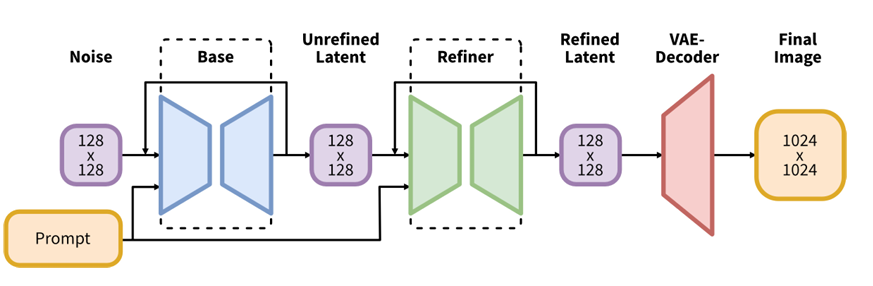


Nguồn: [SDXL pipeline](https://huggingface.co/docs/diffusers/api/pipelines/stable_diffusion/stable_diffusion_xl), [SDXL paper](https://arxiv.org/abs/2307.01952), [Latent Diffusion Models](https://arxiv.org/abs/2112.10752).

## 5. Mở rộng - So sánh scheduler và guidance trên SDXL

Sử dụng các thành phần SDXL đã tải riêng để xây dựng lại pipeline và thực hiện các thí nghiệm mở rộng:

- So sánh các scheduler: Default (Euler), DDIM và DPM-Solver++ với 10, 20 và 50 bước khử nhiễu.

- Khảo sát ảnh hưởng của Guidance Scale đến chất lượng và độ bám sát prompt của ảnh sinh ra.

- Sử dụng cùng latent nhiễu ban đầu để đảm bảo tính nhất quán khi so sánh.

- Đánh giá sự khác biệt về hình ảnh, thời gian suy luận và mức sử dụng bộ nhớ giữa các cấu hình.

In [ ]:
assembled = StableDiffusionXLPipeline(
    vae=vae, text_encoder=text_encoder, text_encoder_2=text_encoder_2,
    tokenizer=tokenizer, tokenizer_2=tokenizer_2, unet=unet,
    scheduler=scheduler, add_watermarker=False,
).to(DEVICE)
assembled.set_progress_bar_config(disable=True)
scheduler_config = assembled.scheduler.config
scheduler_types = [
    ('default', scheduler_class),
    ('DDIM', DDIMScheduler),
    ('DPM-Solver++', DPMSolverMultistepScheduler),
]
shared_noise = input_latents_cpu.to(DEVICE)
scheduler_rows, scheduler_images = [], []
for label, cls in scheduler_types:
    assembled.scheduler = cls.from_config(scheduler_config)
    for steps in (10, 20, 50):
        image, seconds, peak = measure(lambda: pipeline_image(
            assembled, steps=steps, latents=shared_noise))
        filename = f'scheduler_{label.replace("+", "p")}_{steps}.png'
        image.save(OUT / filename)
        scheduler_rows.append(dict(scheduler=label, steps=steps, seed=SEED,
                                   seconds=round(seconds, 3),
                                   peak_allocated_gib=None if peak is None else round(peak, 3)))
        scheduler_images.append((f'{label} / {steps} steps', image))
save_table(scheduler_rows, 'scheduler_results.csv')
scheduler_grid = image_grid(scheduler_images, columns=3)
scheduler_grid.save(OUT / 'scheduler_grid.png')
display(scheduler_grid)
assembled.scheduler = scheduler_class.from_config(scheduler_config)
scheduler = scheduler_class.from_config(scheduler_config)

Nhận xét:

- Số bước khử nhiễu: Ở 10 steps, ảnh còn thiếu chi tiết và bố cục chưa ổn định. Khi tăng lên 20–50 steps, chủ thể rõ hơn, nhưng mức cải thiện từ 20 lên 50 steps không quá lớn trong ví dụ này.
- Default (Euler) và DDIM: Cho kết quả khá tương đồng ở cùng số bước, đặc biệt tại 20 và 50 steps.
- DPM-Solver++:*Khác biệt bố cục rõ hơn ở 10 steps; khi tăng số bước, kết quả gần với hai scheduler còn lại hơn.


In [ ]:
guidance_rows, guidance_images = [], []
for guidance in (1.0, 3.0, 7.5, 12.0, 15.0, 20.0):
    image, seconds, peak = measure(lambda: pipeline_image(
        assembled, guidance=guidance, latents=shared_noise))
    image.save(OUT / f'guidance_{str(guidance).replace(".", "_")}.png')
    guidance_rows.append(dict(guidance_scale=guidance, steps=STEPS, seed=SEED,
                              seconds=round(seconds, 3),
                              peak_allocated_gib=None if peak is None else round(peak, 3)))
    guidance_images.append((f'Guidance {guidance}', image))
save_table(guidance_rows, 'guidance_results.csv')
guidance_grid = image_grid(guidance_images, columns=3)
guidance_grid.save(OUT / 'guidance_grid.png')
display(guidance_grid)

Nhận xét:
- Guidance 1.0: Ảnh mờ, thiếu chi tiết, chủ thể khó nhận diện và bám prompt kém.
- Guidance 3.0: Đã thể hiện đúng nội dung prompt nhưng độ tương phản thấp, hình ảnh chưa rõ nét.
- Guidance 7.5-12.0: Ảnh rõ nét, bố cục cân đối, chủ thể nổi bật và bám sát prompt.
- Guidance 15.0-20.0: Độ tương phản tăng mạnh, màu sắc gắt hơn và xuất hiện một số chi tiết thiếu tự nhiên.

## 6. Mở rộng - Trực quan hóa quá trình khử nhiễu của SDXL

In [ ]:
snapshot_steps = (1, 5, 10, 15, 20, -1)
final_latents, snapshots = manual_denoise(
    PROMPT, input_latents_cpu, steps=STEPS, guidance=GUIDANCE,
    capture_steps=snapshot_steps)
progress_images = []
for step in snapshot_steps:
    image = decode_latents(snapshots[step])
    tag = 'final' if step == -1 else f'{step:02d}'
    image.save(OUT / f'denoise_step_{tag}.png')
    progress_images.append(('Final' if step == -1 else f'Update {step}', image))
progress_grid = image_grid(progress_images, columns=3)
progress_grid.save(OUT / 'denoising_progress.png')
display(progress_grid)

## 7. Mở rộng - SDXL Refiner

- Sử dụng SDXL Refiner để tiếp tục tinh chỉnh ảnh từ SDXL Base, với `strength=0.25`.
- Giữ nguyên prompt và seed để so sánh chất lượng hình ảnh giữa Base và Base + Refiner, đồng thời đo thời gian xử lý bổ sung của Refiner.

In [ ]:
from diffusers import DiffusionPipeline


del assembled, unet, vae, text_encoder, text_encoder_2, tokenizer, tokenizer_2, scheduler
gc.collect()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

REFINER_ID = 'stabilityai/stable-diffusion-xl-refiner-1.0'
REFINER_STRENGTH = 0.25
refiner_kwargs = dict(dtype=DTYPE, use_safetensors=True, add_watermarker=False)
if VARIANT is not None:
    refiner_kwargs['variant'] = VARIANT
refiner = DiffusionPipeline.from_pretrained(REFINER_ID, **refiner_kwargs).to(DEVICE)
refiner.set_progress_bar_config(disable=True)
base_latents = reference_latents_cpu.to(DEVICE)
refined_image, refiner_seconds, refiner_peak = measure(lambda: refiner(
    prompt=PROMPT, negative_prompt=NEGATIVE_PROMPT, image=base_latents,
    strength=REFINER_STRENGTH, num_inference_steps=STEPS,
    guidance_scale=GUIDANCE,
    generator=torch.Generator(device=DEVICE).manual_seed(SEED),
).images[0])
refined_image.save(OUT / 'refiner_image.png')
comparison = image_grid([('SDXL Base', first_image), ('Base + Refiner', refined_image)], columns=2)
comparison.save(OUT / 'base_vs_refiner.png')
display(comparison)
save_table([dict(prompt=PROMPT, seed=SEED, strength=REFINER_STRENGTH,
                 base_seconds=round(first_seconds, 3),
                 refiner_seconds=round(refiner_seconds, 3),
                 total_seconds=round(first_seconds + refiner_seconds, 3),
                 refiner_peak_allocated_gib=None if refiner_peak is None else round(refiner_peak, 3))],
           'refiner_results.csv')
del refiner, base_latents
gc.collect()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

Nhận xét:
- SDXL Base: Ảnh có bố cục cân đối, chủ thể rõ ràng nhưng một số chi tiết và kết cấu bề mặt còn khá mềm.
- Base + Refiner: Cải thiện độ sắc nét, kết cấu trang phục phi hành gia, bộ lông ngựa và bề mặt mặt trăng. Độ tương phản tăng, tuy nhiên một số chi tiết có phần gắt hơn.


## 8. References

- Rombach et al. (2022), *[High-Resolution Image Synthesis with Latent Diffusion Models](https://arxiv.org/abs/2112.10752)*.

- Podell et al. (2023), *[SDXL: Improving Latent Diffusion Models for High-Resolution Image Synthesis](https://arxiv.org/abs/2307.01952)*.

- Hugging Face, *[Diffusers – Stable Diffusion XL Pipeline](https://huggingface.co/docs/diffusers/api/pipelines/stable_diffusion/stable_diffusion_xl)*.

- Hugging Face, *[Stable Diffusion XL Usage Guide](https://huggingface.co/docs/diffusers/using-diffusers/sdxl)*.

- Stability AI, *[Stable Diffusion XL Base 1.0](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0)*.

- Stability AI, *[Stable Diffusion XL Refiner 1.0](https://huggingface.co/stabilityai/stable-diffusion-xl-refiner-1.0)*.